---
title: "L6-10 · Design a quantum causal experiment"
short_title: "Design a quantum causal experiment"
subtitle: "A causal experiment is designed backwards from what each hypothesis forbids: find a statistic whose allowed ranges differ, size the run so that sampling error cannot fake a violation, add controls for every assumption the ranges rely on, and report an overlap as a non-result."
description: "Design, size and pre-register an experiment that can falsify a common-cause explanation or a direct-cause explanation of the correlations between two qubits, and state what each possible result does and does not show."
tags: [level-6, coursebook]
---

(lesson-l6-10)=

:::{div}
:class: qcai-meta
![Level 6 icon](../../_static/icons/qicon-level-6.svg) **Level 6 · Graduate** · about 135 minutes  
**Big idea.** A causal experiment is designed backwards from what each hypothesis forbids: find a statistic whose allowed ranges differ, size the run so that sampling error cannot fake a violation, add controls for every assumption the ranges rely on, and report an overlap as a non-result.  
**Before this lesson.** [L6-02](#lesson-l6-02), [L6-04](#lesson-l6-04), [L6-05](#lesson-l6-05), [L6-09](#lesson-l6-09)  
**Lab.** [Quantum causal inference](../../labs/11-quantum-causal-inference.ipynb)
:::

## What you will be able to do

- State common-cause and cause-effect hypotheses for two qubits as sets of models under an explicit protocol, and list the operations each regime of the experiment allows.
- Prove that $S = c_x + c_y + c_z$ lies in $[-3, 1]$ for every common cause and in $[-1, 3]$ for every cause-effect channel in the protocol, and use this to write falsification rules.
- Derive a Hoeffding sample size that controls both error rates for composite hypotheses, compute it for a named alternative, and compare it with the exact binomial power.
- Write a pre-registered analysis plan with controls, and say what each outcome, including an inconclusive one, licenses you to report.

## Why this matters

Two qubits in a lab show strong correlations. One colleague says a source prepares them together; another says qubit A is sent through a channel and becomes qubit B. Both stories can explain correlations, and the familiar instinct, take more data, does not help if every quantity you measure is predicted equally well by both. More samples cannot resolve a distinction absent from the design ([L6-05](#lesson-l6-05)).

This lesson builds the experiment from the other end. It starts with what each hypothesis forbids, finds a statistic whose allowed ranges differ, proves those ranges, and then asks how many shots are needed so that chance alone cannot produce a false verdict for any model in the hypothesis, not only for a convenient one. The result is a pre-registered plan with controls, in which an inconclusive outcome is a legitimate result to report, and in which a violation of both hypotheses means something specific.

:::{dropdown} Key terms

**Falsification rule**
: A pre-declared condition on the data under which a hypothesis is rejected, with a stated bound on the probability of rejecting it when it is true.

**Composite hypothesis**
: A hypothesis that is a set of models (for example, every two-qubit state), so an error bound must hold for every member.

**Measure-and-send protocol**
: Pauli $\sigma_i$ is measured on qubit A (the post-measurement state continues) and $\sigma_i$ on qubit B, for $i = x, y, z$; the record is the three correlations $c_i = \mathbb{E}[ab]$.

**Hoeffding margin**
: The deviation $t_N = \sqrt{6\ln(1/\alpha)/N}$ that the estimate of $S$ exceeds with probability at most $\alpha$, for $N$ shots in each of three settings.

**Power**
: The probability that the test rejects a hypothesis when a stated alternative is true.

**Positive and negative controls**
: Runs on devices whose answer is known (a plain wire, a known source, a product state) that check the apparatus can produce, and can avoid producing, a violation.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l6_10 as _lessonfigs

## From a question to two hypotheses

The question is: *is the correlation between qubits $A$ and $B$ produced by a common source, or by a direct channel from $A$ to $B$?* The first job is to turn each answer into a set of models, with the systems and the laboratory operations named. Ried and coauthors studied this question for two qubits with the measure-and-send protocol used below and reported a photonic experiment [@ried2015]; MacLean and coauthors later realized coherent mixtures of the two structures [@maclean]. The design here follows the logic of those works but is a self-contained teaching design, with its own statistic and sample-size analysis.

:::{figure} ../../_static/animations/l6_10_pipeline.mp4
:alt: Two causal graphs, a source Lambda feeding A and B, and A feeding B through a channel E; then eight boxes in a snake from Question to Decision, each with the concrete choice of this lesson.
:width: 100%

The two hypotheses, then the design pipeline: question, hypotheses, operations, predictions, statistic, sample size, controls, decision.
:::

:::{dropdown} What the animation shows
The scene first draws the common-cause graph, a source $\Lambda$ with arrows to $A$ and $B$, labeled $H_{cc}$: shared state $\rho_{AB}$, and the cause-effect graph, $A \to B$ through a channel $\mathcal{E}$, labeled $H_{ce}$. It then builds eight boxes in a snake, with the concrete choice for each: Question, common source or direct channel; Hypotheses, any shared state against any channel; Operations, Pauli pairs XX, YY, ZZ with A maximally mixed; Predictions, $S \le 1$ for a common cause and $S \ge -1$ for a channel; Statistic, $S = c_x + c_y + c_z$; Sample size, $N = 579$ shots per setting from a Hoeffding bound; Controls, readout, marginals, a known wire and a known source; Decision, falsify the common cause if $\hat S > 1 + 0.196$. The final line reads that every number is fixed before any data are taken.
:::

:::{prf:definition} The two hypotheses under the protocol
:label: def-l6-10-hyp
In the measure-and-send protocol, for each $i \in \{x, y, z\}$ run $N$ shots: measure $\sigma_i$ on $A$ with outcome $a = \pm 1$, then $\sigma_i$ on $B$ with outcome $b = \pm 1$, and record $c_i = \mathbb{E}[ab]$.

- $H_{cc}$ (common cause): $A$ and $B$ are the two halves of some two-qubit state $\rho_{AB}$, arbitrary, so $c_i = \operatorname{Tr}[\rho_{AB}\,\sigma_i \otimes \sigma_i]$.
- $H_{ce}$ (cause-effect): $A$ is maximally mixed when it is measured, its post-measurement state passes through some channel $\mathcal{E}$, arbitrary, and the output is $B$.

Both hypotheses are composite: each is the set of all models of its form. $H_{ce}$ is the direct-cause hypothesis of [L6-05](#lesson-l6-05).
:::

```{mermaid}
graph LR
  L[Source] --> A1[A]
  L --> B1[B]
  A2[A] -->|channel| B2[B]
  M[Mixture weight p] -.-> A2
  M -.-> L
```

*Left: the common-cause structure. Right: the cause-effect structure. A classical weight $p$ can select between them shot by shot; such mixtures are in neither pure hypothesis.*

:::{prf:lemma} Correlations under each hypothesis
:label: lem-l6-10-corr
Under $H_{ce}$, with the Choi operator $J = \sum_{jk}|j\rangle\langle k| \otimes \mathcal{E}(|j\rangle\langle k|)$ of [L6-02](#lesson-l6-02),
$$c_i = \tfrac12\operatorname{Tr}[\sigma_i\,\mathcal{E}(\sigma_i)] = \operatorname{Tr}\big[(\sigma_i^{T} \otimes \sigma_i)\,J/2\big].$$
:::

:::{prf:proof}
With $A$ maximally mixed, $a = \pm 1$ each with probability $\tfrac12$ and the post-measurement state is $(I + a\sigma_i)/2$. So $\mathbb{E}[ab] = \sum_a \tfrac12\,a\operatorname{Tr}[\sigma_i\,\mathcal{E}((I + a\sigma_i)/2)] = \tfrac14\sum_a (a\operatorname{Tr}[\sigma_i\mathcal{E}(I)] + \operatorname{Tr}[\sigma_i\mathcal{E}(\sigma_i)]) = \tfrac12\operatorname{Tr}[\sigma_i\mathcal{E}(\sigma_i)]$. For the second form, $\operatorname{Tr}[(M \otimes N)J] = \sum_{jk}\langle k|M|j\rangle\operatorname{Tr}[N\mathcal{E}(|j\rangle\langle k|)] = \operatorname{Tr}[N\mathcal{E}(M^{T})]$; put $M = \sigma_i^{T}$, $N = \sigma_i$. $\square$
:::

## What each regime lets you do

Which operations are available decides which distinctions are possible ([L6-04](#lesson-l6-04)). Two regimes are worth separating.

**Regime I: interventions on $A$.** If you can discard whatever arrives at $A$ and prepare a state of your choice there (a replacement intervention), the question becomes a signaling test. Under $H_{cc}$, $B$'s state is $\operatorname{Tr}_A\rho_{AB}$ whatever you prepare. Under $H_{ce}$, $B$'s state is $\mathcal{E}(\tau)$ for the prepared $\tau$.

:::{prf:proposition} Six preparations detect every non-constant channel
:label: prop-l6-10-six
Let $\tau$ range over the six Pauli eigenstates $|0\rangle, |1\rangle, |\pm\rangle, |\pm i\rangle$ and let $B$ be measured in all three Pauli bases. If the statistics at $B$ do not depend on $\tau$, then $\mathcal{E}$ is a replacement channel $\mathcal{E}(\tau) = \operatorname{Tr}(\tau)\,\beta$. Conversely every replacement channel, and every common cause, gives $\tau$-independent statistics.
:::

:::{prf:proof}
Pauli expectations determine a qubit state, so $\mathcal{E}(\tau) = \beta$ for all six $\tau$. By linearity $\mathcal{E}(Z) = \mathcal{E}(|0\rangle\langle 0|) - \mathcal{E}(|1\rangle\langle 1|) = 0$, and likewise $\mathcal{E}(X) = \mathcal{E}(Y) = 0$, while $\mathcal{E}(I) = 2\beta$. Hence $\mathcal{E}(M) = \operatorname{Tr}(M)\beta$ for every operator $M$. The converse is immediate. $\square$
:::

So with interventions a non-constant channel is detectable, but a replacement channel is a direct-cause structure with no detectable influence: it is indistinguishable from no arrow at all. That is a faithfulness-type assumption that must be stated, not a fact quantum theory supplies. Interventions also say nothing about whether a common source is present in addition to the channel.

**Regime II: observation only.** If you cannot replace $A$, only measure it and let it continue, the measure-and-send protocol of Definition [](#def-l6-10-hyp) is what you have. Classically, passive observation of two variables cannot separate a common cause from a direct cause without further assumptions. With qubits, the three correlations carry structural information, as the next section proves. The rest of the lesson designs the Regime II experiment.

## A statistic whose allowed ranges differ

:::{prf:theorem} Separating ranges
:label: thm-l6-10-ranges
Let $S = c_x + c_y + c_z$ in the measure-and-send protocol.

1. Under $H_{cc}$: $-3 \le S \le 1$. $S = 1$ exactly when $\rho_{AB}$ is supported on the triplet subspace, and $S = -3$ exactly for the singlet $|\Psi^-\rangle$.
2. Under $H_{ce}$: $-1 \le S \le 3$. $S = 3$ exactly for the identity channel.

So $S > 1$ is impossible for every common cause and $S < -1$ is impossible for every cause-effect channel.
:::

:::{prf:proof}
*Common cause.* $S = \operatorname{Tr}[\rho_{AB}(XX + YY + ZZ)]$, and $XX + YY + ZZ = 2\,\mathrm{SWAP} - I$ (check it on $|00\rangle$, $|01\rangle$, $|10\rangle$, $|11\rangle$). $\mathrm{SWAP}$ has eigenvalue $+1$ on the three-dimensional triplet subspace and $-1$ on the singlet, so $XX + YY + ZZ$ has eigenvalues $1, 1, 1, -3$, and $S$ is a convex combination of them, with the stated equality cases.

*Cause-effect.* By Lemma [](#lem-l6-10-corr), and since $X^{T} = X$, $Y^{T} = -Y$, $Z^{T} = Z$ in the computational basis, $S = \operatorname{Tr}[(XX - YY + ZZ)\,J/2]$. Now $XX - YY + ZZ$ is the partial transpose (on the first factor) of $XX + YY + ZZ$, that is $2\,\mathrm{SWAP}^{T_A} - I = 2|\Omega\rangle\langle\Omega| - I$ with $|\Omega\rangle = |00\rangle + |11\rangle$. Since $\langle\Omega|\Omega\rangle = 2$, its eigenvalues are $3, -1, -1, -1$. Because $\mathcal{E}$ is completely positive and trace preserving, $J/2$ is a density operator, so $-1 \le S \le 3$, with $S = 3$ iff $J/2 = |\Omega\rangle\langle\Omega|/2$, the Choi state of the identity channel. $\square$
:::

$$
XX + YY + ZZ = 2\,\mathrm{SWAP} - I, \qquad XX - YY + ZZ = 2|\Omega\rangle\langle\Omega| - I
$$ (eq-l6-10-spectra)

:::{figure} ../../_static/animations/l6_10_witness.mp4
:alt: A derivation that turns the common-cause value of S into a spectrum with largest eigenvalue 1, and the cause-effect value into a spectrum with smallest eigenvalue -1; then a number line from -3 to 3 with a blue common-cause interval, a red cause-effect interval, a gray overlap labeled inconclusive, and a dot that slides as the mixing weight grows.
:width: 100%

Equation [](#eq-l6-10-spectra) turns into two ranges on one number line. The mixture point $S = 3v(2p - 1)$ crosses from 'falsifies $H_{ce}$' through 'no verdict' to 'falsifies $H_{cc}$'.
:::

:::{dropdown} What the animation shows
The statistic $S = c_x + c_y + c_z$ appears. The common-cause line $S_{cc} = \operatorname{Tr}[\rho_{AB}(XX + YY + ZZ)]$ transforms into $XX + YY + ZZ = 2\,\mathrm{SWAP} - I$ and then into eigenvalues $1, 1, 1, -3$, so $-3 \le S_{cc} \le 1$. The cause-effect line $S_{ce} = \operatorname{Tr}[(XX - YY + ZZ)J/2]$, with the note that $Y^{T} = -Y$ makes this the partial transpose, transforms into $XX - YY + ZZ = 2|\Omega\rangle\langle\Omega| - I$ and eigenvalues $3, -1, -1, -1$, so $-1 \le S_{ce} \le 3$. A number line from $-3$ to $3$ shows the common-cause interval $[-3, 1]$ in blue, the cause-effect interval $[-1, 3]$ in red, and the overlap $[-1, 1]$ shaded as inconclusive. For the mixture model $S = 3v(2p - 1)$ with $v = 0.9$, a dot slides as $p$ goes from 0 to 1: at $p = 0$ it sits at $-2.70$ and falsifies $H_{ce}$; between $p \approx 0.31$ and $0.69$ there is no verdict; at $p = 0.75$, $S = 1.35$ and it falsifies $H_{cc}$.
:::

:::{prf:example} The planned alternative: a mixture
:label: ex-l6-10-mixture
Let each shot use a direct depolarized wire $\rho \mapsto v\rho + (1 - v)I/2$ with probability $p$, and a noisy singlet source $v|\Psi^-\rangle\langle\Psi^-| + (1 - v)I/4$ with probability $1 - p$. Both have $A$ maximally mixed, so the $A$ data cannot reveal the structure. The wire gives $c = v(1, 1, 1)$, the source gives $c = -v(1, 1, 1)$, so the mixture gives $S = 3v(2p - 1)$. With $v = 0.9$: $p = 0$ gives $-2.7$ (outside the cause-effect range), $p = 0.75$ gives $S = 1.35$ (outside the common-cause range), and every $p$ with $|2p - 1| \le 1/(3v)$, about $0.31 \le p \le 0.69$, lands in the overlap. A pure noisy wire ($p = 1$) falsifies $H_{cc}$ only if $3v > 1$, that is $v > 1/3$. Note the labeling: here $p$ is the weight of the direct wire, whereas in [L6-04](#lesson-l6-04) and in Ried et al. $p$ is the weight of the common cause.
:::

:::{prf:remark} What the overlap means
Every point of $[-1, 1]$ is reachable by both hypotheses, so a true value there gives no verdict at any sample size. In particular, every product state gives $|c_x| + |c_y| + |c_z| \le 1$ and so lies in the overlap: in this protocol, an unambiguous common-cause verdict needs entanglement, as Lab 11 shows. Not rejecting $H_{cc}$ is never evidence for $H_{cc}$ by itself.
:::

## How many shots: a bound that holds for every model

The estimate is $\hat S = \hat c_x + \hat c_y + \hat c_z$, each $\hat c_i$ the mean of $N$ products $ab \in \{-1, 1\}$. Because $H_{cc}$ is a set of models, an error bound computed for one convenient model (say, a normal approximation at the boundary) is not enough. A concentration inequality gives a bound that holds for every model at once.

:::{prf:lemma} Hoeffding's lemma
:label: lem-l6-10-hlemma
[@hoeffding1963] If $Y \in [a, b]$ and $\mathbb{E}Y = 0$, then $\mathbb{E}\,e^{\lambda Y} \le e^{\lambda^2(b - a)^2/8}$ for every real $\lambda$.
:::

:::{prf:proof}
By convexity, $e^{\lambda y} \le \frac{b - y}{b - a}e^{\lambda a} + \frac{y - a}{b - a}e^{\lambda b}$ on $[a, b]$. Taking expectations with $\mathbb{E}Y = 0$ gives $\mathbb{E}e^{\lambda Y} \le e^{L(h)}$ with $h = \lambda(b - a)$, $\pi = -a/(b - a) \in [0, 1]$ and $L(h) = -h\pi + \ln(1 - \pi + \pi e^{h})$. Then $L(0) = L'(0) = 0$ and $L''(h) = u(1 - u) \le \tfrac14$ with $u = \pi e^{h}/(1 - \pi + \pi e^{h})$, so Taylor's theorem gives $L(h) \le h^2/8$. $\square$
:::

:::{prf:theorem} Hoeffding bound for the estimate of S
:label: thm-l6-10-hoeffding
If the $3N$ shots are independent, then for every model and every $t > 0$ [@hoeffding1963],
$$P(\hat S - S \ge t) \le e^{-N t^2/6}, \qquad P(\hat S - S \le -t) \le e^{-N t^2/6}.$$
:::

:::{prf:proof}
$\hat S - S = \frac1N\sum_{j=1}^{3N}(Y_j - \mathbb{E}Y_j)$ with $Y_j \in [-1, 1]$. By Markov's inequality and independence, for $\lambda > 0$, $P(\sum_j (Y_j - \mathbb{E}Y_j) \ge Nt) \le e^{-\lambda N t}\prod_j \mathbb{E}e^{\lambda(Y_j - \mathbb{E}Y_j)} \le e^{-\lambda N t + 3N\lambda^2 \cdot 4/8}$ by the lemma (range 2). Minimizing over $\lambda$ at $\lambda = t/3$ gives $e^{-N t^2/6}$. The lower tail follows by applying this to $-Y_j$. $\square$
:::

:::{prf:proposition} Valid tests and a sample size
:label: prop-l6-10-size
Let $t_N = \sqrt{6\ln(1/\alpha)/N}$. Reject $H_{cc}$ if $\hat S > 1 + t_N$ and reject $H_{ce}$ if $\hat S < -1 - t_N$. Then each true hypothesis is rejected with probability at most $\alpha$, for every model in it, and the chance of any false rejection is at most $2\alpha$. If the true $S \ge 1 + \Delta$, the test rejects $H_{cc}$ with probability at least $1 - \beta$ whenever
$$N \ge \frac{6\big(\sqrt{\ln(1/\alpha)} + \sqrt{\ln(1/\beta)}\big)^2}{\Delta^2}.$$
:::

:::{prf:proof}
Under $H_{cc}$, $S \le 1$ by Theorem [](#thm-l6-10-ranges), so $P(\hat S > 1 + t_N) \le P(\hat S - S > t_N) \le e^{-N t_N^2/6} = \alpha$; the other test is symmetric, and the union bound gives $2\alpha$. If $S \ge 1 + \Delta$ with $\Delta > t_N$, then $P(\hat S \le 1 + t_N) \le P(\hat S - S \le -(\Delta - t_N)) \le e^{-N(\Delta - t_N)^2/6}$, which is at most $\beta$ iff $\sqrt{N}\Delta \ge \sqrt{6\ln(1/\alpha)} + \sqrt{6\ln(1/\beta)}$. $\square$
:::

**The numbers.** Take $\alpha = 0.025$ per test (at most $0.05$ in total), $\beta = 0.1$, and the planned alternative of Example [](#ex-l6-10-mixture) with $v = 0.9$, $p = 0.75$, so $S = 1.35$ and $\Delta = 0.35$. Then $6(\sqrt{\ln 40} + \sqrt{\ln 10})^2/0.35^2 \approx 578.96$, so $N = 579$ shots per setting, $1737$ in all, and $t_{579} = \sqrt{6\ln 40/579} \approx 0.196$. The pre-registered rule is: falsify $H_{cc}$ if $\hat S > 1.196$, falsify $H_{ce}$ if $\hat S < -1.196$.

:::{figure} ../../_static/animations/l6_10_shots.mp4
:alt: Two exact sampling distributions of the estimate of S, one centered at 1 and one at 1.35, narrowing as the number of shots grows from 30 to 579, with a dashed threshold line moving left toward 1.2.
:width: 100%

Exact sampling distributions of $\hat S$ at the boundary null ($S = 1$) and the planned alternative ($S = 1.35$), with the threshold $1 + t_N$, for $N = 30, 100, 300, 579$.
:::

:::{dropdown} What the animation shows
Two curves show the exact distribution of $\hat S$ for the triplet state at the boundary of $H_{cc}$ ($S = 1$, blue) and for the planned alternative ($S = 1.35$, red); for these models $\hat S = (2K - 3N)/N$ with $K$ binomial on $3N$ trials. A dashed line marks the threshold $1 + t_N$. At $N = 30$ the curves overlap heavily, $t_N = 0.859$ and the power is $0.040$. At $N = 100$, $t_N = 0.470$ and the power is $0.220$. At $N = 300$, $t_N = 0.272$ and the power is $0.815$. At $N = 579$, $t_N = 0.196$ and the power is $0.992$. A closing note says that the Hoeffding guarantee holds for every common-cause model, not only the boundary one.
:::

:::{figure} ../../_static/animations/l6_10_power.mp4
:alt: A graph of rejection probability against shots per setting: a red exact power curve rising steeply to 1 and a violet guaranteed curve rising later; a vertical line at N = 579 where the guarantee reaches 0.9.
:width: 100%

Exact power and the distribution-free guarantee against $N$ for the alternative $S = 1.35$. The planned $N = 579$ is where the guarantee reaches $0.9$.
:::

:::{dropdown} What the animation shows
Axes show the shots per setting $N$ from 0 to 1000 and the probability of rejecting $H_{cc}$ from 0 to 1, with a horizontal guide at 0.9. As $N$ sweeps, a red dot traces the exact binomial power for $S = 1.35$ and a violet dot traces the Hoeffding guarantee $1 - e^{-N(\Delta - t_N)^2/6}$, which stays at 0 until $t_N < \Delta$. A vertical line marks $N = 579$. The text reports the exact power $0.992$, the guarantee $\ge 0.9$, and the sample-size formula $N \ge 6(\sqrt{\ln(1/\alpha)} + \sqrt{\ln(1/\beta)})^2/\Delta^2$.
:::


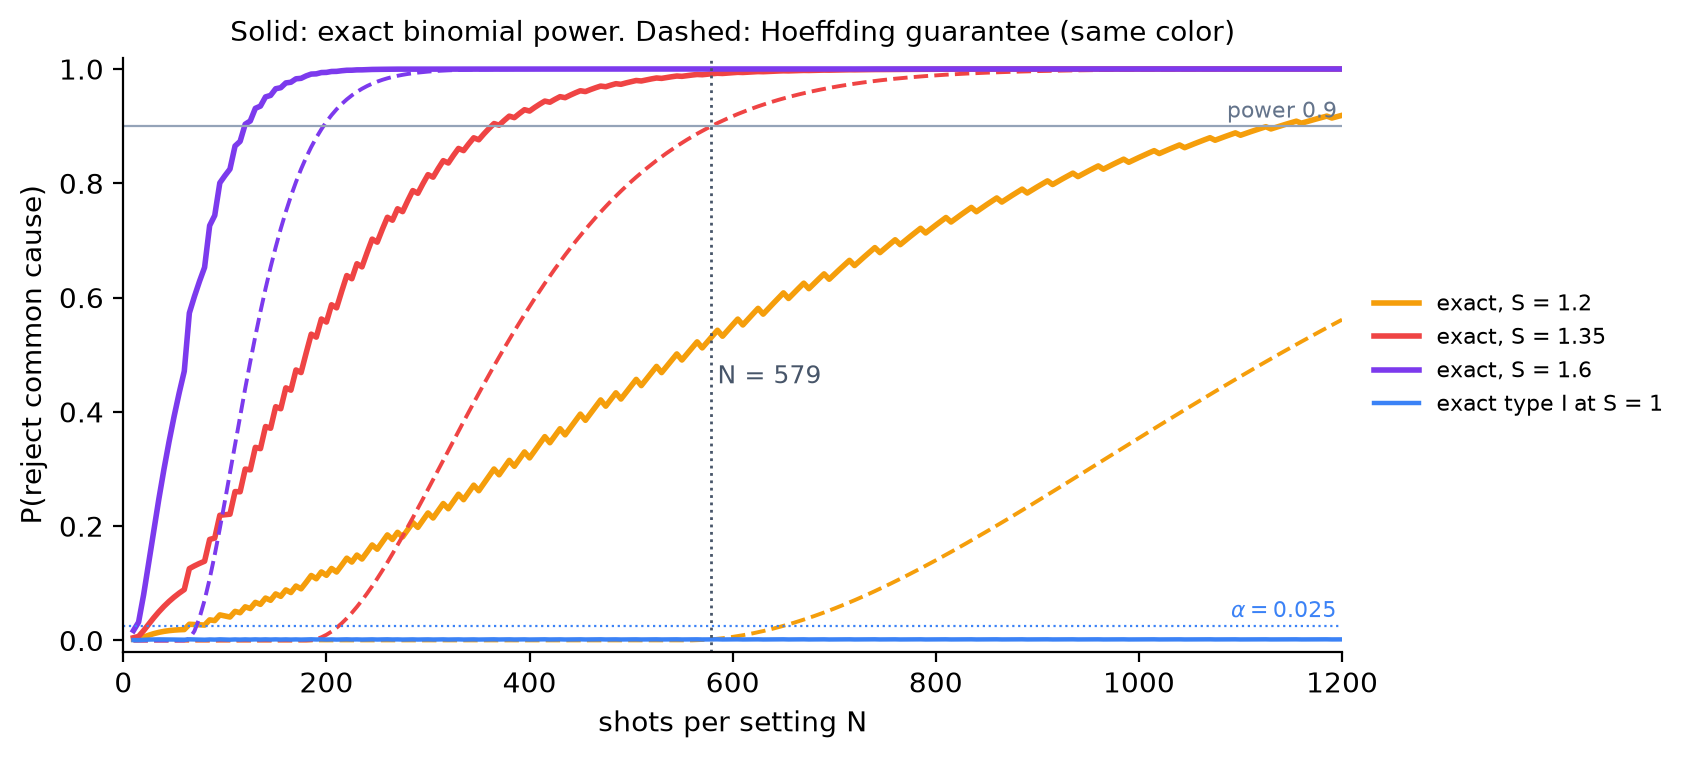

In [2]:
_show_mpl(_lessonfigs.power_curves())

*Solid curves: exact power for three alternatives ($S = 1.2, 1.35, 1.6$, with $c = (S/3)(1, 1, 1)$). Dashed curves of the same color: the Hoeffding guarantee. Blue: exact type I error at the boundary null, far below $\alpha = 0.025$. The sawtooth comes from the discreteness of the binomial distribution.*

:::{prf:remark} Why not plan with the exact power?
For $S = 1.35$ the exact power first reaches $0.9$ at $N = 363$ and stays above it from $N = 370$, well below 579, and the exact type I error at the triplet state is about $0.0019$. The exact calculation, however, assumes a particular model in each hypothesis ($c$ along the diagonal). The Hoeffding bound assumes only independence and bounded outcomes, so it protects every model in the composite hypothesis. The price of that guarantee is about 60 percent more shots. Report which one you planned with.
:::

## Controls, the analysis plan, and what would falsify what

Theorem [](#thm-l6-10-ranges) relies on four assumptions, and each needs a control: trusted Pauli measurements on both qubits; a maximally mixed $A$ under $H_{ce}$; independent shots (no drift, no memory); and the identification of the recorded ports with the qubits $A$ and $B$ that the hypotheses describe.

:::{warning} A stuck detector looks like a perfect wire
If both detectors always report $+1$, every product $ab$ is $+1$ and $\hat S = 3$, the value of the identity channel. Symmetric, uncorrelated readout flips only shrink $|c_i|$ (each $c_i$ is multiplied by $(1 - 2e_A)(1 - 2e_B)$), which is conservative; biased or correlated readout errors are not. That is why the marginals are recorded and checked, not only the products.
:::

:::{prf:algorithm} Pre-registered analysis plan
:label: alg-l6-10-plan
1. **Fix in advance:** $\alpha = 0.025$ per test, $N = 579$ shots per setting, the thresholds $\pm 1.196$, and the order of settings (randomized and interleaved with control runs in blocks).
2. **Readout calibration:** prepare $|0\rangle, |1\rangle, |\pm\rangle, |\pm i\rangle$ on each qubit; estimate flip rates; stop if they are biased beyond a pre-set tolerance.
3. **Positive controls:** a known wire in place of the device (expect $\hat S$ near $3$ times the measured visibility) and a known entangled source (expect $\hat S$ near $-3$ times its visibility).
4. **Negative control:** a product source such as $|00\rangle$, which sits on the boundary $S = 1$; it must not be rejected more often than $\alpha$.
5. **Assumption check:** the $A$ marginals $\langle a\rangle_i$ must be zero within a Hoeffding margin; if not, $H_{ce}$ as defined is already falsified, and the ranges must be rederived for a non-mixed input.
6. **Main run:** compute $\hat c_x, \hat c_y, \hat c_z$ and $\hat S$; apply the rule; report $\hat S$ with its margin $t_N$ whatever the verdict.
7. **Replication:** confirm any verdict on an independent run before reporting it as established.
:::

| Result | Falsifies | Does not show |
|---|---|---|
| $\hat S > 1 + t_N$ | every common-cause model in the protocol | that the channel is the identity, or that no source is present at all |
| $\hat S < -1 - t_N$ | every cause-effect model with mixed input | which entangled source produced it |
| $\lvert\hat S\rvert \le 1 + t_N$ | nothing | that either hypothesis is true; the design cannot decide |
| both thresholds crossed in separate runs, or a control fails | the assumptions of the design | anything about the causal structure until the failure is explained |


In [3]:
_show(_lessonfigs.statistic_vs_mixing())

**Explore.** Seeded simulated experiments for each mixing weight $p$ (with $v = 0.9$). Move the slider to change the shots per setting. Red points falsify the common cause, blue points falsify the cause-effect channel, gray points give no verdict; the gray band is the overlap $[-1, 1]$.

:::{dropdown} What the figure shows
The horizontal axis is the mixing weight $p$ of the direct channel from 0 to 1; the vertical axis is $S$ from $-3.6$ to $3.6$. A line shows the true $S = 3v(2p - 1)$. For each $p$ in steps of $0.05$ a point shows a simulated $\hat S$ with error bar $\pm t_N$, colored by the verdict. Dashed lines at $\pm(1 + t_N)$ mark the rejection thresholds, and a shaded band marks $[-1, 1]$. With $N = 30$ the thresholds sit at about $\pm 1.86$ and few points are decisive; with $N = 579$ they sit at $\pm 1.196$; with $N = 3000$ they approach $\pm 1$, but points with true $S$ inside the band never become decisive.
:::

## Simulate the experiment

A qubit-level simulation with seeded shots. Each shot first draws the structure (direct wire with probability $p$, noisy singlet source otherwise), then samples outcomes from the Born rule for the chosen Pauli pair. The run uses the planned $N = 579$ and applies the pre-registered rule and the $A$-marginal control.


In [4]:
import math
import numpy as np
from qcai import science as s

PAULI = {"x": s.X, "y": s.Y, "z": s.Z}
KEYS_A = np.array([1, 1, -1, -1]); KEYS_B = np.array([1, -1, 1, -1])     # outcome pairs (a, b)
proj_pm = lambda P, a: (s.I2 + a * P) / 2

def table_common(rho, P):
    """Joint outcome probabilities when sigma_i is measured on both halves of a shared state."""
    return np.array([np.real(np.trace(rho @ np.kron(proj_pm(P, a), proj_pm(P, b)))) for a, b in zip(KEYS_A, KEYS_B)])

def table_channel(kraus, P):
    """A maximally mixed, measured (eigenstate kept), sent through the channel, then measured."""
    return np.array([0.5 * np.real(np.trace(proj_pm(P, b) @ s.apply_kraus(proj_pm(P, a), kraus)))
                     for a, b in zip(KEYS_A, KEYS_B)])

V, P_MIX = 0.9, 0.75
rho_cc = V * s.dm(s.bell_state("psi-")) + (1 - V) * np.eye(4) / 4      # noisy singlet source
kraus_ce = s.depolarizing_kraus(1 - V)                                  # rho -> V rho + (1 - V) I/2

# exact correlations of the two pure structures and of the mixture
for name, tab in (("common cause", table_common), ("cause-effect", table_channel)):
    arg = rho_cc if tab is table_common else kraus_ce
    c = [float(KEYS_A * KEYS_B @ tab(arg, P)) for P in PAULI.values()]
    print(f"{name:13s} c = {np.round(c, 4)}  S = {sum(c):+.3f}")
S_mix = 3 * V * (2 * P_MIX - 1)
print(f"mixture p = {P_MIX}: S = 3v(2p - 1) = {S_mix:.3f}")

def run_experiment(p_mix, n, rng):
    """n shots per Pauli setting; each shot first draws the structure (direct channel with prob p_mix)."""
    c_hat, a_mean = {}, {}
    for k, P in PAULI.items():
        tabs = (table_common(rho_cc, P), table_channel(kraus_ce, P))
        direct = rng.random(n) < p_mix
        idx = np.where(direct, rng.choice(4, size=n, p=tabs[1]), rng.choice(4, size=n, p=tabs[0]))
        c_hat[k] = float(np.mean(KEYS_A[idx] * KEYS_B[idx]))
        a_mean[k] = float(np.mean(KEYS_A[idx]))
    return c_hat, a_mean

ALPHA, BETA, DELTA = 0.025, 0.10, S_mix - 1
N = math.ceil(6 * (math.sqrt(math.log(1 / ALPHA)) + math.sqrt(math.log(1 / BETA))) ** 2 / DELTA ** 2)
t_N = math.sqrt(6 * math.log(1 / ALPHA) / N)
rng = np.random.default_rng(2026)
c_hat, a_mean = run_experiment(P_MIX, N, rng)
S_hat = sum(c_hat.values())
print(f"\nplanned N = {N} per setting ({3 * N} shots), t_N = {t_N:.3f}")
print("estimates", {k: round(v, 3) for k, v in c_hat.items()}, f" S_hat = {S_hat:.3f}")
verdict = ("falsifies common cause" if S_hat > 1 + t_N else
           "falsifies cause-effect" if S_hat < -1 - t_N else "no verdict")
print("decision:", verdict)
m = math.sqrt(2 * math.log(2 * 3 / 0.01) / N)            # A-marginal control, family-wise 0.01
print("A marginals", {k: round(v, 3) for k, v in a_mean.items()}, f" control margin {m:.3f}:",
      "pass" if all(abs(v) <= m for v in a_mean.values()) else "FAIL")

common cause  c = [-0.9 -0.9 -0.9]  S = -2.700
cause-effect  c = [0.9 0.9 0.9]  S = +2.700
mixture p = 0.75: S = 3v(2p - 1) = 1.350

planned N = 579 per setting (1737 shots), t_N = 0.196
estimates {'x': 0.461, 'y': 0.461, 'z': 0.482}  S_hat = 1.404
decision: falsifies common cause
A marginals {'x': -0.06, 'y': 0.047, 'z': -0.033}  control margin 0.149: pass


The design checks: exact binomial power and the Hoeffding guarantee at $N = 579$, the exact type I error at two boundary null models, a simulated false-rejection rate, the two spectra and a random search over states and channels, and the Regime I signaling statistic $D = P(b = 0 \mid |0\rangle) - P(b = 0 \mid |1\rangle)$, which equals $pv$ in the mixture model and $0$ for every common cause.


In [5]:
# exact power (binomial) and the Hoeffding guarantee; the type I error at two boundary null models
def binom_pmf(n, q):
    k = np.arange(n + 1)
    logc = np.array([math.lgamma(n + 1) - math.lgamma(i + 1) - math.lgamma(n - i + 1) for i in k])
    return np.exp(logc + k * math.log(q) + (n - k) * math.log1p(-q))

thr = lambda n: math.floor(n * (4 + math.sqrt(6 * math.log(1 / ALPHA) / n)) / 2)
power = lambda S, n: float(binom_pmf(3 * n, (1 + S / 3) / 2)[thr(n) + 1:].sum())   # c = (S/3)(1, 1, 1)
print(f"exact power at N = {N}: {power(S_mix, N):.3f};  Hoeffding guarantee "
      f"{1 - math.exp(-N * (DELTA - t_N) ** 2 / 6):.3f}")
print(f"exact type I at the triplet state (c = (1/3, 1/3, 1/3)): {power(1.0, N):.4f}")
pmf = np.convolve(binom_pmf(N, 0.5), binom_pmf(N, 0.5))
print(f"exact type I at |00> (c = (0, 0, 1)): {pmf[np.arange(pmf.size) + N > thr(N)].sum():.4f}")

# coverage of the Hoeffding test by simulation at the boundary null, N = 100
g = np.random.default_rng(7)
n = 100
K = g.binomial(n, (1 + 1 / 3) / 2, size=(20000, 3)).sum(axis=1)
S_rep = (2 * K - 3 * n) / n
print(f"false rejections in 20000 simulated boundary experiments: {np.mean(S_rep > 1 + math.sqrt(6 * math.log(40) / n)):.4f}"
      f" (guaranteed <= {ALPHA})")

# the witness spectra, and random states and channels
XX, YY, ZZ = (np.kron(P, P) for P in (s.X, s.Y, s.Z))
print("eig(XX+YY+ZZ) =", np.round(np.linalg.eigvalsh(XX + YY + ZZ), 6), " eig(XX-YY+ZZ) =", np.round(np.linalg.eigvalsh(XX - YY + ZZ), 6))
SWAP = np.eye(4)[[0, 2, 1, 3]]
pt = lambda M: M.reshape(2, 2, 2, 2).transpose(2, 1, 0, 3).reshape(4, 4)   # transpose on the first factor
omega = np.array([1, 0, 0, 1.0])
assert np.allclose(XX + YY + ZZ, 2 * SWAP - np.eye(4)) and np.allclose(pt(SWAP), np.outer(omega, omega))
worst_cc, worst_ce = -9.0, 9.0
for _ in range(300):
    G = g.normal(size=(4, 4)) + 1j * g.normal(size=(4, 4)); rho = G @ G.conj().T; rho /= np.trace(rho)
    worst_cc = max(worst_cc, float(np.real(np.trace(rho @ (XX + YY + ZZ)))))
    Q = np.linalg.qr(g.normal(size=(6, 6)) + 1j * g.normal(size=(6, 6)))[0][:, :2].reshape(2, 3, 2)
    kr = [Q[:, k, :] for k in range(3)]
    worst_ce = min(worst_ce, sum(float(KEYS_A * KEYS_B @ table_channel(kr, P)) for P in PAULI.values()))
print(f"300 random states: max S = {worst_cc:.3f} (<= 1);  300 random channels: min S = {worst_ce:.3f} (>= -1)")

# intervention regime: replace A by |0> or |1>, measure Z on B
n_int = 200
def b_zero_prob(prep):
    direct = s.apply_kraus(s.dm(prep), kraus_ce)[0, 0].real
    return P_MIX * direct + (1 - P_MIX) * 0.5                 # common-cause branch: B stays I/2
p0, p1 = b_zero_prob(s.KET0), b_zero_prob(s.KET1)
D_hat = g.binomial(n_int, p0) / n_int - g.binomial(n_int, p1) / n_int
print(f"\nintervention: D = {p0 - p1:.3f} (= p v), D_hat = {D_hat:.3f}, one-sided margin {math.sqrt(math.log(1 / ALPHA) / n_int):.3f}")

exact power at N = 579: 0.992;  Hoeffding guarantee 0.900
exact type I at the triplet state (c = (1/3, 1/3, 1/3)): 0.0019
exact type I at |00> (c = (0, 0, 1)): 0.0004
false rejections in 20000 simulated boundary experiments: 0.0016 (guaranteed <= 0.025)
eig(XX+YY+ZZ) = [-3.  1.  1.  1.]  eig(XX-YY+ZZ) = [-1. -1. -1.  3.]
300 random states: max S = 0.891 (<= 1);  300 random channels: min S = -0.950 (>= -1)

intervention: D = 0.675 (= p v), D_hat = 0.645, one-sided margin 0.136


:::{prf:remark} Simulations are not experiments
The simulation checks that the analysis behaves as designed when its assumptions hold. It cannot check the assumptions: real readout bias, drift, leakage out of the qubit subspace, or a structure outside both hypotheses can all produce a crossing of a threshold. Those are what the controls in Algorithm [](#alg-l6-10-plan) are for.
:::

## Worked example

:::{admonition} Sizing a run for a weaker alternative
:class: tip

A team expects a pure noisy wire with visibility $v = 0.45$ and wants to falsify $H_{cc}$ with $\alpha = 0.025$ and power at least $0.9$ under the Hoeffding guarantee. Find $S$, $\Delta$, the required $N$ per setting, the threshold, and decide whether a result $\hat S = 1.21$ at that $N$ falsifies $H_{cc}$.

1. A pure wire is $p = 1$ in Example [](#ex-l6-10-mixture), so $S = 3v = 1.35$ and $\Delta = S - 1 = 0.35$, the same gap as the planned mixture.
2. Sample size: $N \ge 6(\sqrt{\ln 40} + \sqrt{\ln 10})^2/0.35^2 = 6(1.9206 + 1.5174)^2/0.1225 \approx 578.96$, so $N = 579$ per setting.
3. Threshold: $t_{579} = \sqrt{6 \cdot 3.6889/579} \approx 0.196$, so reject $H_{cc}$ if $\hat S > 1.196$.
4. Decision: $1.21 > 1.196$, so $H_{cc}$ is rejected at level $0.025$. The margin is small; the plan's replication step applies before the verdict is reported as established.

**Result.** $N = 579$ per setting, threshold $1.196$; $\hat S = 1.21$ falsifies every common-cause model in the protocol at level $0.025$, subject to replication and to the controls passing.
:::

## Exercises

**1. (Core)** Compute $S$ in the protocol for (a) the state $|\Phi^+\rangle$ as a common cause, (b) the identity channel, (c) the bit-flip channel $\rho \mapsto X\rho X$. Which hypotheses can each be falsified by, with enough shots?

:::{dropdown} Solution
(a) $c = (1, -1, 1)$, $S = 1$: inside the overlap, no verdict at any $N$. (b) $c = (1, 1, 1)$, $S = 3$: outside $[-3, 1]$, so it can falsify $H_{cc}$. (c) $c_i = \tfrac12\operatorname{Tr}[\sigma_i X\sigma_i X] = (1, -1, -1)$, $S = -1$: on the boundary of the cause-effect range, inside the overlap, no verdict.
:::

**2. (Core)** With $\alpha = 0.025$, what is the threshold $1 + t_N$ for $N = 300$ shots per setting, and what is the smallest $\Delta$ for which the Hoeffding guarantee gives power $0.9$ at that $N$?

:::{dropdown} Solution
$t_{300} = \sqrt{6\ln 40/300} = \sqrt{0.07378} \approx 0.272$, threshold $1.272$. Power $0.9$ needs $\sqrt{300}\,\Delta \ge \sqrt{6\ln 40} + \sqrt{6\ln 10} = 4.705 + 3.717 = 8.421$, so $\Delta \ge 0.486$.
:::

**3. (Stretch)** Show that every product state $\rho_A \otimes \rho_B$ gives $|S| \le 1$, so that in this protocol only entangled sources can falsify $H_{ce}$.

:::{dropdown} Solution
For a product state $c_i = r_i s_i$ with Bloch vectors $\vec r, \vec s$ of length at most 1. Then $|S| \le \sum_i |r_i||s_i| \le |\vec r||\vec s| \le 1$ by Cauchy-Schwarz. Mixtures of product states (separable states) are convex combinations, so $|S| \le 1$ too, and $S < -1$ requires entanglement.
:::

**4. (Stretch)** Readout on each qubit flips the outcome with probability $e$, independently and symmetrically. Show that every $c_i$ is multiplied by $(1 - 2e)^2$, and find the largest $e$ for which the pure identity channel can still falsify $H_{cc}$ with enough shots.

:::{dropdown} Solution
A symmetric flip multiplies each outcome by an independent $\pm 1$ with mean $1 - 2e$, so $\mathbb{E}[ab]$ is multiplied by $(1 - 2e)^2$. The identity channel then gives $S = 3(1 - 2e)^2$, which exceeds 1 iff $(1 - 2e)^2 > 1/3$, i.e. $e < (1 - 1/\sqrt3)/2 \approx 0.211$.
:::

**5. (Challenge)** Under $H_{ce}$, suppose $A$ is not maximally mixed but has Bloch vector $\vec r$. Show that $c_i = \tfrac12\operatorname{Tr}[\sigma_i\mathcal{E}(\sigma_i)] + \tfrac12 r_i\operatorname{Tr}[\sigma_i\mathcal{E}(I)]$. Then take $A$ in $|0\rangle$ and the channel $\mathcal{E} = \mathcal{Z} \circ \mathcal{D}_\gamma$, where $\mathcal{D}_\gamma$ is amplitude damping toward $|1\rangle$ ($|0\rangle\langle 0| \mapsto (1 - \gamma)|0\rangle\langle 0| + \gamma|1\rangle\langle 1|$, $|1\rangle\langle 1| \mapsto |1\rangle\langle 1|$, $|0\rangle\langle 1| \mapsto \sqrt{1 - \gamma}\,|0\rangle\langle 1|$) and $\mathcal{Z}(\rho) = Z\rho Z$. Compute $S(\gamma)$ and its minimum. What does this say about the marginal check?

:::{dropdown} Solution
Outcome $a$ has probability $(1 + a r_i)/2$ and leaves $(I + a\sigma_i)/2$, so $\mathbb{E}[ab] = \sum_a \frac{1 + a r_i}{2}\cdot a\cdot\tfrac12\big(\operatorname{Tr}[\sigma_i\mathcal{E}(I)] + a\operatorname{Tr}[\sigma_i\mathcal{E}(\sigma_i)]\big) = \tfrac12\operatorname{Tr}[\sigma_i\mathcal{E}(\sigma_i)] + \tfrac12 r_i\operatorname{Tr}[\sigma_i\mathcal{E}(I)]$. For the given channel, $\mathcal{E}(X) = -\sqrt{1 - \gamma}\,X$, $\mathcal{E}(Y) = -\sqrt{1 - \gamma}\,Y$, $\mathcal{E}(Z) = (1 - \gamma)Z$ and $\mathcal{E}(I) = I - \gamma Z$. With $\vec r = (0, 0, 1)$: $c_x = c_y = -\sqrt{1 - \gamma}$ and $c_z = (1 - \gamma) - \gamma$, so $S(\gamma) = 1 - 2\gamma - 2\sqrt{1 - \gamma}$. With $u = \sqrt{1 - \gamma}$, $S = 2u^2 - 2u - 1$, minimized at $u = \tfrac12$ ($\gamma = \tfrac34$) with $S = -1.5 < -1$. So a cause-effect structure with a biased input would be wrongly reported as falsifying $H_{ce}$. The bound $S \ge -1$ was proved only for a maximally mixed input; here $\langle a\rangle_z = 1$, which the marginal check in the plan detects at once.
:::

**6. (Challenge)** Design the Regime I (intervention) version: with replacement preparations $|0\rangle$ and $|1\rangle$ at $A$, $n$ shots each, and a $Z$ measurement at $B$, give a level-$\alpha$ test of $H_{cc}$ based on $\hat D = \hat P(b = 0 \mid |0\rangle) - \hat P(b = 0 \mid |1\rangle)$, its sample size for the mixture model with $v = 0.9$, $p = 0.75$, and one cause-effect channel it cannot detect.

:::{dropdown} Solution
Under $H_{cc}$, $D = 0$ for every model. $\hat D$ is a sum of $2n$ independent terms each in a range of length $1/n$, so Hoeffding gives $P(\hat D - D \ge t) \le e^{-2t^2/(2n \cdot n^{-2})} = e^{-n t^2}$. Reject $H_{cc}$ if $\hat D > \sqrt{\ln(1/\alpha)/n}$. In the mixture model $D = pv = 0.675$; power $1 - \beta$ is guaranteed when $\sqrt{n}\,D \ge \sqrt{\ln(1/\alpha)} + \sqrt{\ln(1/\beta)}$, i.e. $n \ge (1.9206 + 1.5174)^2/0.675^2 \approx 25.9$, so $n = 26$ per preparation. It cannot detect a channel that ignores the $Z$ basis, such as measure-$X$-and-prepare-$Z$, $\mathcal{E}(\tau) = \langle +|\tau|+\rangle|0\rangle\langle 0| + \langle -|\tau|-\rangle|1\rangle\langle 1|$, which sends both $|0\rangle$ and $|1\rangle$ to $I/2$; Proposition [](#prop-l6-10-six) says all six preparations and three bases are needed to catch every non-constant channel.
:::

## Check your understanding

**1. In the measure-and-send protocol, the estimate is $\hat S = 0.6 \pm 0.05$ with a very large $N$. What should be reported?**

- **A.** The direct channel is confirmed because $S > -1$
- **B.** Both hypotheses are falsified
- **C.** The common cause is confirmed because $S < 1$
- **D.** No verdict: both hypotheses allow $S = 0.6$

:::{dropdown} Show the answer
**D. No verdict: both hypotheses allow $S = 0.6$**

$0.6$ lies in the overlap $[-1, 1]$ of the two ranges, so no model in either hypothesis is excluded. More shots cannot change that.
:::

**2. Why is the Hoeffding bound used for planning instead of a normal approximation at one boundary model?**

- **A.** It always gives fewer shots
- **B.** It removes the need for controls
- **C.** It bounds the error for every model in the composite hypothesis
- **D.** It is exact for binomial data

:::{dropdown} Show the answer
**C. It bounds the error for every model in the composite hypothesis**

A hypothesis such as 'some two-qubit state' contains infinitely many models. Hoeffding uses only independence and bounded outcomes, so the level-$\alpha$ guarantee holds for all of them; the price is more shots than an exact calculation for one model.
:::

**3. Both detectors are stuck and always report $+1$. What does the analysis report?**

- **A.** Nothing, because the products are not recorded
- **B.** $\hat S = 3$, a spurious falsification of the common cause unless the marginal and readout controls catch it
- **C.** $\hat S = -3$, a falsification of the direct channel
- **D.** $\hat S = 0$, no verdict

:::{dropdown} Show the answer
**B. $\hat S = 3$, a spurious falsification of the common cause unless the marginal and readout controls catch it**

Every product $ab$ is $+1$, so each $\hat c_i = 1$ and $\hat S = 3$. The marginals $\langle a\rangle = \langle b\rangle = 1$ fail the assumption check, which is why the plan records them.
:::

**4. Under the Choi convention $J = \sum_{jk}|j\rangle\langle k| \otimes \mathcal{E}(|j\rangle\langle k|)$, which expression gives $\operatorname{Tr}[N\,\mathcal{E}(M)]$?** *(Review of [L6-02](#lesson-l6-02))*

- **A.** $\operatorname{Tr}[(M \otimes N)J]$
- **B.** $\operatorname{Tr}[(M^{T} \otimes N)J]$
- **C.** $\operatorname{Tr}[(N \otimes M)J]$
- **D.** $\operatorname{Tr}[(M^{\dagger} \otimes N)J]$

:::{dropdown} Show the answer
**B. $\operatorname{Tr}[(M^{T} \otimes N)J]$**

$\operatorname{Tr}[(M' \otimes N)J] = \operatorname{Tr}[N\mathcal{E}(M'^{T})]$, so $M' = M^{T}$. Forgetting the transpose flips the sign of $c_y$ and swaps the two ranges of Theorem [](#thm-l6-10-ranges).
:::

## Common misconceptions

- **"If the data do not reject the common cause, the common cause is supported."** Values in $[-1, 1]$ are allowed by both hypotheses. Failing to reject is a non-result under this design and must be reported as one.
- **"With enough shots any two causal hypotheses can be told apart."** Shots shrink the margin $t_N$ but cannot move the true $S$ out of the overlap. Separation needs a statistic whose allowed ranges differ at the true model, which is a property of the design.
- **"Rejecting both pure hypotheses is a contradiction, so the experiment failed."** It cannot happen within one run (the two rejection regions are disjoint), but separate runs or failed controls can point outside both pure hypotheses: to a mixture of structures, to a structure with both a source and a channel, or to broken assumptions. Each is a substantive result once the controls are checked.
- **"A significant result means the channel is the identity."** Rejecting $H_{cc}$ excludes every common-cause model. It says nothing about which channel or mixture produced the data, and it does not exclude a source acting alongside a channel.

:::{caution} Scope and limits
The design assumes trusted Pauli measurements, independent shots, a maximally mixed qubit $A$ under the cause-effect hypothesis, and the two pure structures as the hypotheses. Mixtures of structures, a source and a channel acting together, coherent superpositions of structures, and systems larger than qubits are outside both hypotheses and are not tested. Conventions: Choi operator $J = \sum_{jk}|j\rangle\langle k| \otimes \mathcal{E}(|j\rangle\langle k|)$ as in `qcai.science.choi`, transpose in the computational basis (so $Y^{T} = -Y$), outcomes $\pm 1$, natural logarithms. The stated level of the cause-effect test holds only for an exactly mixed input: by the biased-input formula of the fifth exercise, a bias $\vec r$ can loosen the bound $S \ge -1$, so passing the marginal check is necessary for using that test but does not correct for a small residual bias. The simulations check the analysis, not the physics, and none of this is a claim of quantum advantage for causal inference.
:::

:::{seealso} Where this leads
Level 7 returns to identifiability and estimation for larger quantum causal models, where full process tomography and causal discovery algorithms replace a single witness [@giarmatzi; @costa]. Entropic constraints are another way to separate causal structures with latent systems [@chaves], and the pseudo-density-matrix approach gives an observational scheme that distinguishes more structures for two qubits measured at two times [@hypothesis].
:::

:::{dropdown} For instructors

**Why this lesson.** Students meet quantum causal models as theory; this lesson makes them do what an experimental collaborator must: state hypotheses as sets, find what they forbid, size a run with a guarantee that survives composite nulls, and write down what each result means [@ried2015; @costa; @barrett].

**Teaching notes.**

- Start by asking students to propose a statistic before showing the theorem; many propose $c_z$ alone and can be shown that $c_z = 1$ is allowed by both hypotheses.
- Derive $XX + YY + ZZ = 2\,\mathrm{SWAP} - I$ on the board from the action on the computational basis; the partial-transpose step then needs only $Y^{T} = -Y$.
- Use the interactive at $N = 30$ and $N = 3000$ to separate sampling uncertainty from structural non-identifiability; the points inside the gray band never become decisive.
- Have groups write the pre-registered plan before running the code, then compare their thresholds and controls with Algorithm [](#alg-l6-10-plan).

**Assessment.** The core exercises test the ranges and the threshold arithmetic; the stretch exercises test the role of entanglement and of readout error; the challenge exercises test whether students can redo the design for a biased input and for the intervention regime.

**Going further.** Extend the hypotheses to probabilistic mixtures of the two structures and ask which values of $c$ certify a nonzero direct-cause weight; compare with the experiment on coherent mixtures [@maclean]. For full structure learning from process data, see the algorithm of Giarmatzi and Costa [@giarmatzi].

:::

## References

This lesson draws on [@ried2015; @maclean; @costa; @barrett; @giarmatzi; @chaves; @hypothesis; @nielsenchuang; @hoeffding1963].

**Further reading.**

- [@ried2015]: The two-qubit common-cause versus cause-effect question with the measure-and-send protocol, and a photonic experiment.
- [@maclean]: An experiment on coherent mixtures of common-cause and cause-effect relations.
- [@hypothesis]: An observational scheme based on space-time pseudo-density matrices that distinguishes five causal structures.

**Next:** [L7-01 · Define the learning task](#lesson-l7-01)
